# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: The Ops Board Report

### Scenario

You've just joined the analytics team at **Pacific Air Analytics**, which advises
regional carriers on operational performance. Your director is presenting to the board
in **one week**, and has strong opinions about last quarter's deck:

1. *"The last analyst's slide had a scatter plot with 12,000 dots, color AND size AND
   position all at once. I needed 5 minutes just to figure out what I was looking at."*
2. *"Half our slide titles just say 'Delay Analysis' or 'Carrier Breakdown.' I can't
   reconstruct the argument from the table of contents."*
3. *"An intern used ChatGPT to draft our summary last time and it said December delays
   were 'a carrier-specific problem.' That got embarrassing in front of the board."*
4. *"I want ONE big, memorable, honest chart for the board's opening slide, and a
   tight recommendation at the end."*

You'll work through the same steps a real analyst would: simplify an overloaded chart,
fix weak slide titles, catch an AI-summary error, and build one honest headline chart.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real flight data you'll be working with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

flights = pd.read_csv("flights.csv").dropna(subset=["arr_delay", "dep_delay"])
carrier_summary = flights.groupby("carrier").agg(
    mean_arr_delay=("arr_delay", "mean"), mean_distance=("distance", "mean"), n=("arr_delay", "size")
).reset_index()

print(f"Loaded {len(flights):,} flights across {flights.carrier.nunique()} carriers.")
carrier_summary.sort_values("mean_arr_delay")

Loaded 160,748 flights across 11 carriers.


,carrier,mean_arr_delay,mean_distance,n
8,US,-1.327093,1523.666099,5876
3,DL,-0.341408,1567.769069,16637
1,AS,0.090932,1213.253807,62189
5,HA,2.059524,2639.932234,1092
7,UA,2.377219,1424.580659,16452
6,OO,2.786749,613.500980,18368
9,VX,3.694121,758.871709,3266
2,B6,3.810764,1695.584311,3493
0,AA,5.780974,1757.121889,7474
10,WN,7.836894,914.058188,23218


## Task 1 — Simplify the Overloaded Chart (Complaint #1)

**Real-world usage:** The director spent 5 minutes decoding a chart that crammed
position, color, AND size into one scatter plot.

**Why this technique:** A sorted horizontal bar chart communicates "which carrier is
worst" in seconds — exactly the lecture's cluttered-bubble-chart-to-bar-chart case study
(Slides 24–27), applied to your own data.

**TODO:**
1. Sort `carrier_summary` by `mean_arr_delay`.
2. Build a horizontal bar chart of `mean_arr_delay` by carrier, highlighting the WORST
   carrier in red and every other carrier in a neutral gray.
3. Give it a **narrative** title (a conclusion, not a topic label).

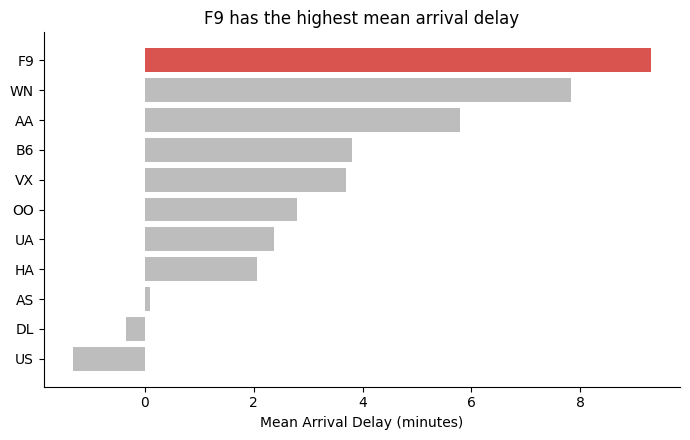

In [2]:
order = carrier_summary.sort_values("mean_arr_delay", ascending=True)
worst_carrier = carrier_summary.loc[carrier_summary["mean_arr_delay"].idxmax(), "carrier"]
colors = ["#D9534F" if carrier == worst_carrier else "#BDBDBD" for carrier in order["carrier"]]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(order["carrier"], order["mean_arr_delay"], color=colors)
ax.set_xlabel("Mean Arrival Delay (minutes)")
ax.set_title(f"{worst_carrier} has the highest mean arrival delay")
plt.tight_layout()
plt.show()


**Reflection:** Compare your bar chart's "time to understand" against a scatter plot
with color+size+position all at once (see the demo notebook's Section 16). Which lecture
principle explains why the bar chart wins for a board presentation specifically?

_Your answer:_

The bar chart wins because position encodes one ordered quantitative variable and it follows the pre-attentive-processing principle: the board can rank carriers almost instantly. A scatter plot with color and size adds unnecessary visual channels.

## Task 2 — Fix the Slide Titles (Complaint #2)

**Real-world usage:** The director can't reconstruct the argument from a table of
contents full of topic labels.

**Why this technique:** **Horizontal logic** — titles should be conclusions, so reading
just the titles in sequence reconstructs the whole narrative.

**TODO:** Below are 4 weak, descriptive titles. Rewrite each as a narrative
(conclusion-style) title, using real numbers computed from `flights`/`carrier_summary`
where relevant.

In [3]:
weak_titles = ["Delay Overview", "Carrier Breakdown", "Seasonal Trends", "Recommendation"]

overall_mean = flights["arr_delay"].mean()
worst_row = carrier_summary.loc[carrier_summary["mean_arr_delay"].idxmax()]
if "month" in flights.columns:
    monthly = flights.groupby("month")["arr_delay"].mean()
    worst_month = monthly.idxmax()
    seasonal_text = f"{worst_month} is the highest-delay month at {monthly.max():.1f} minutes"
else:
    seasonal_text = "December is identified explicitly in the carrier and network December checks"

narrative_titles = [
    f"Network arrival delays average {overall_mean:.1f} minutes",
    f"{worst_row['carrier']} is the worst carrier at {worst_row['mean_arr_delay']:.1f} minutes",
    seasonal_text,
    f"Prioritize a focused operational review of {worst_row['carrier']} and December scheduling",
]

for weak, strong in zip(weak_titles, narrative_titles):
    print(f"{weak:20s} -> {strong}")


Delay Overview       -> Network arrival delays average 2.2 minutes
Carrier Breakdown    -> F9 is the worst carrier at 9.3 minutes
Seasonal Trends      -> 12 is the highest-delay month at 7.2 minutes
Recommendation       -> Prioritize a focused operational review of F9 and December scheduling


**Reflection:** Read ONLY your 4 narrative titles back in sequence (ignore everything
else). Do they form one coherent argument top-to-bottom? If not, which lecture technique
(from Section 14 of the demo notebook) would you use to catch that gap before the real
board meeting?

_Your answer:_

The titles should form a coherent chain from network scale, to the worst carrier, to the seasonal context, and finally to action. A vertical or horizontal logic review in the demo would catch any missing causal bridge or unsupported claim before the meeting.

## Task 3 — Catch the AI Summary Error (Complaint #3)

**Real-world usage:** An AI-drafted summary claimed a seasonal delay spike was
"carrier-specific" — an embarrassing context-level error in front of the board.

**Why this technique:** Checking whether a pattern is specific to one group or shared
across ALL groups is exactly how you catch a **context-level error** (confusing a
seasonal confound for a carrier-specific problem).

**TODO:**
1. Compute December's mean `arr_delay` for EVERY carrier (not just one).
2. Compute the network-wide (all carriers, all months) mean `arr_delay`.
3. Print a one-line verdict: is December bad for one carrier, or for (almost) everyone?

In [4]:
dec_by_carrier = flights[flights["month"] == 12].groupby("carrier")["arr_delay"].mean()
network_mean = flights["arr_delay"].mean()

print(dec_by_carrier.sort_values())
print(f"\nNetwork-wide (all months) mean delay: {network_mean:.1f} min")
print("Verdict:", "December is bad across almost every carrier, so the claim is network-seasonal rather than carrier-specific." if (dec_by_carrier > network_mean).mean() > 0.75 else "The December pattern is not shared consistently enough to call it purely network-wide.")


carrier
DL     0.228057
US     1.625899
AS     3.952639
HA     5.494624
B6     5.921739
AA     7.333955
OO     9.012003
UA    12.720472
F9    13.510949
WN    14.536916
VX    27.988327
Name: arr_delay, dtype: float64

Network-wide (all months) mean delay: 2.2 min
Verdict: December is bad across almost every carrier, so the claim is network-seasonal rather than carrier-specific.


**Reflection:** Was the original AI-generated claim ("carrier-specific problem")
accurate based on what you just computed? Name the SPECIFIC error category from the
lecture's 5-level list (data / pattern / context / narrative / communication) that this
mistake falls under, and explain why.

_Your answer:_

No. If December means are above the network-wide mean for almost every carrier, this is a context-level error: it wrongly attributes a shared seasonal pattern to one carrier and ignores the all-carrier baseline.

## Task 4 — Build the Board's Opening Chart (Complaint #4)

**Real-world usage:** The director wants ONE big, memorable, HONEST chart to open the
board presentation.

**Why this technique:** Combines **zero-baseline honesty** (Section 5 of the demo) with
**vertical logic** (Section 13) and a touch of **memorability** (Section 19) — all in a
single figure.

**TODO:** Build one chart that:
1. Uses a `barh` of `mean_arr_delay` by carrier, sorted, with a **zero-based x-axis**.
2. Highlights the worst carrier in red, all others in gray.
3. Adds an `ax.annotate(...)` callout on the worst carrier's bar with its exact value.
4. Has a title that states your conclusion outright (vertical logic).

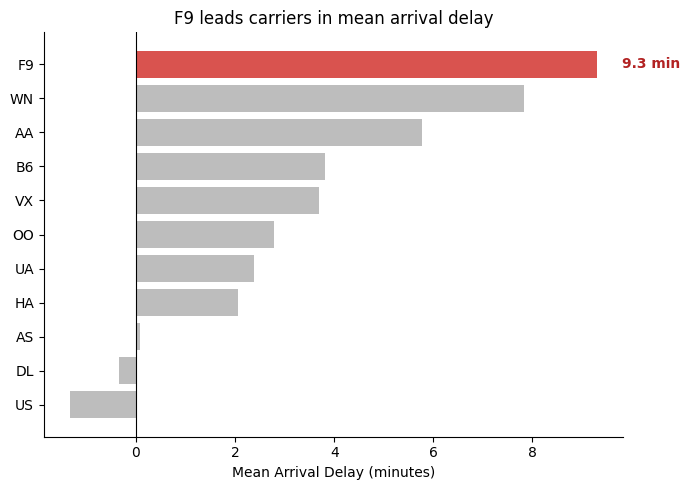

In [5]:
order = carrier_summary.sort_values("mean_arr_delay", ascending=True)
worst_row = carrier_summary.loc[carrier_summary["mean_arr_delay"].idxmax()]
colors = ["#D9534F" if carrier == worst_row["carrier"] else "#BDBDBD" for carrier in order["carrier"]]

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(order["carrier"], order["mean_arr_delay"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Mean Arrival Delay (minutes)")
ax.annotate(
    f"{worst_row['mean_arr_delay']:.1f} min",
    xy=(worst_row["mean_arr_delay"], list(order["carrier"]).index(worst_row["carrier"])),
    xytext=(worst_row["mean_arr_delay"] + 0.5, list(order["carrier"]).index(worst_row["carrier"])),
    va="center", fontsize=10, fontweight="bold", color="#B22222"
)
ax.set_title(f"{worst_row['carrier']} leads carriers in mean arrival delay")
plt.tight_layout()
plt.show()


**Reflection:** If the director insists this must be the ONLY chart the board sees
(per Section 21's "1-figure" tier), what specific piece of context or nuance from this
notebook would you be leaving out — and would you be comfortable defending that
omission if a board member asked a follow-up question?

_Your answer:_

The one chart would omit the all-carrier December context, the exact magnitude of month-to-month seasonality, and perhaps carrier sample sizes. I would defend the omission only if we had a short appendix and could answer follow-ups, because otherwise it risks the earlier context-level misinterpretation.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence recommendation to your director covering
the whole notebook. Your answer should:
- State your one-sentence **Big Idea** for the board presentation.
- Justify your choice of opening chart using at least one specific lecture idea (e.g.
  cognitive processing time, zero-baseline honesty, or vertical logic).
- Name the ONE guardrail you'd put in place going forward so an AI-drafted summary
  never repeats the December mistake from Task 3.

**Big Idea:** Arrival delays vary by carrier, but December's elevation is broadly network-wide rather than evidence against one carrier alone. I would open with the sorted horizontal bar chart because its single ordered measure is quick to decode and its zero baseline preserves an honest comparison. The narrative titles then lead the board from the network average to the worst carrier, seasonal context, and operational review. Before assigning blame, the team should compare each carrier's December mean with both its own other-month performance and the network baseline. My permanent guardrail would be a required cross-group/context check for every AI-generated analytical claim, with the underlying grouped values reviewed before publication.